# Customer Dataset Dimensionality Reduction using PCA
**Aim:** Apply PCA to customer spending features, compare PCA without scaling and PCA after StandardScaler, and interpret the transformed data.

Dataset: UCI Wholesale Customers (440 records). PCA uses the six annual spending features; `Channel` and `Region` are retained only as descriptive columns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error


## 1. Load the dataset
The dataset is downloaded from the UCI Machine Learning Repository. Internet access is required for this cell.

In [2]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv'
df = pd.read_csv(url)
print('Shape:', df.shape)
display(df.head())
display(df.info())


Shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


None

## 2. Select numerical customer spending features
PCA is applied to the six spending columns. `Channel` and `Region` are categorical descriptors and are not included in this PCA experiment.

In [3]:
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X = df[features].copy()
print('Missing values:', X.isnull().sum().sum())
display(X.describe().round(2))


Missing values: 0


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,12000.30,5796.27,7951.28,3071.93,2881.49,1524.87
std,12647.33,7380.38,9503.16,4854.67,4767.85,2820.11
min,3.00,55.00,3.00,25.00,3.00,3.00
25%,3127.75,1533.00,2153.00,742.25,256.75,408.25
50%,8504.00,3627.00,4755.50,1526.00,816.50,965.50
75%,16933.75,7190.25,10655.75,3554.25,3922.00,1820.25
max,112151.00,73498.00,92780.00,60869.00,40827.00,47943.00


## 3. Exploratory data analysis

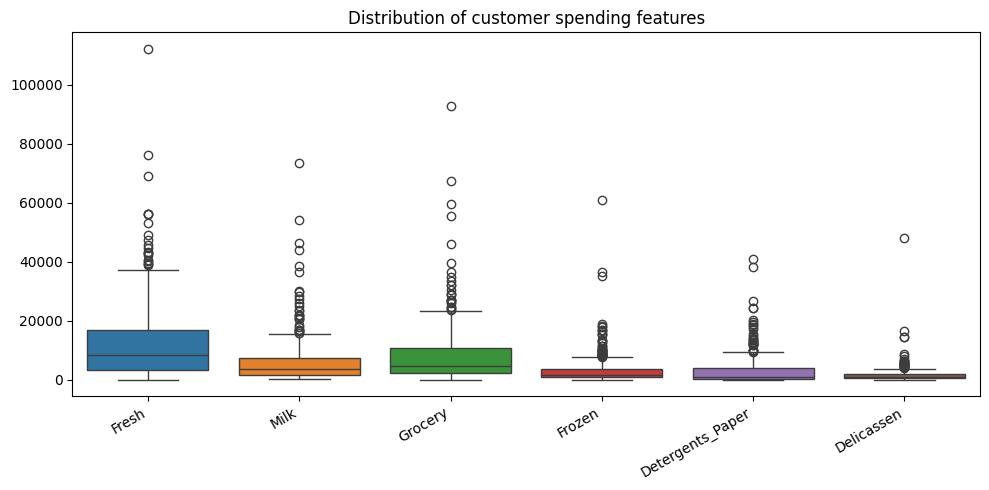

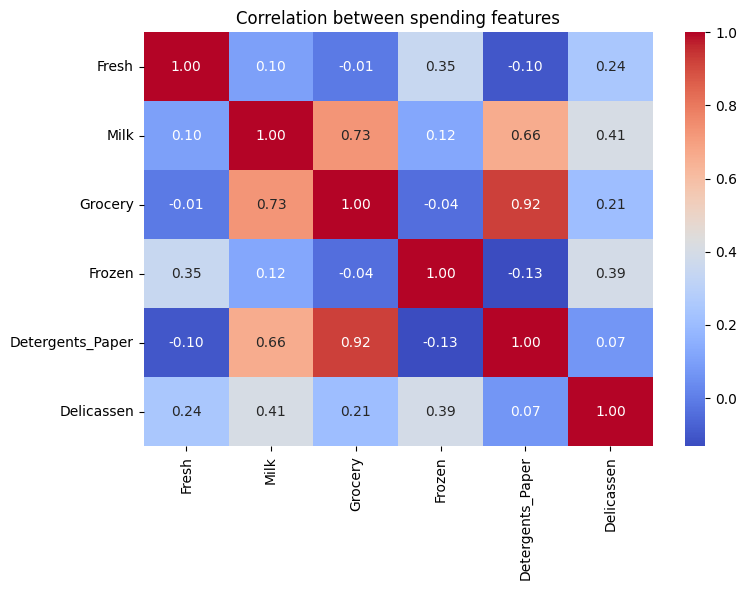

In [4]:
plt.figure(figsize=(10,5))
sns.boxplot(data=X)
plt.xticks(rotation=30, ha='right')
plt.title('Distribution of customer spending features')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation between spending features')
plt.tight_layout()
plt.show()


## 4. PCA without feature scaling
PCA is variance-based. Features with larger numerical scales can dominate when the original data is used directly.

In [5]:
pca_raw = PCA()
X_raw_pca = pca_raw.fit_transform(X)
raw_variance = pca_raw.explained_variance_ratio_
raw_table = pd.DataFrame({'Principal Component':[f'PC{i+1}' for i in range(len(features))], 'Explained Variance Ratio':raw_variance, 'Cumulative Variance':np.cumsum(raw_variance)})
display(raw_table.round(4))


,Principal Component,Explained Variance Ratio,Cumulative Variance
0,PC1,0.4596,0.4596
1,PC2,0.4052,0.8648
2,PC3,0.0700,0.9348
3,PC4,0.0440,0.9788
4,PC5,0.0150,0.9939
5,PC6,0.0061,1.0000


## 5. StandardScaler followed by PCA
StandardScaler transforms each feature to approximately zero mean and unit standard deviation before PCA.

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca_scaled = PCA()
X_scaled_pca = pca_scaled.fit_transform(X_scaled)
scaled_variance = pca_scaled.explained_variance_ratio_
scaled_table = pd.DataFrame({'Principal Component':[f'PC{i+1}' for i in range(len(features))], 'Explained Variance Ratio':scaled_variance, 'Cumulative Variance':np.cumsum(scaled_variance)})
display(scaled_table.round(4))


,Principal Component,Explained Variance Ratio,Cumulative Variance
0,PC1,0.4408,0.4408
1,PC2,0.2838,0.7246
2,PC3,0.1233,0.8479
3,PC4,0.0940,0.9419
4,PC5,0.0476,0.9895
5,PC6,0.0105,1.0000


## 6. Compare explained variance

,Component,PCA without scaling,PCA after StandardScaler
0,PC1,0.4596,0.4408
1,PC2,0.4052,0.2838
2,PC3,0.0700,0.1233
3,PC4,0.0440,0.0940
4,PC5,0.0150,0.0476
5,PC6,0.0061,0.0105


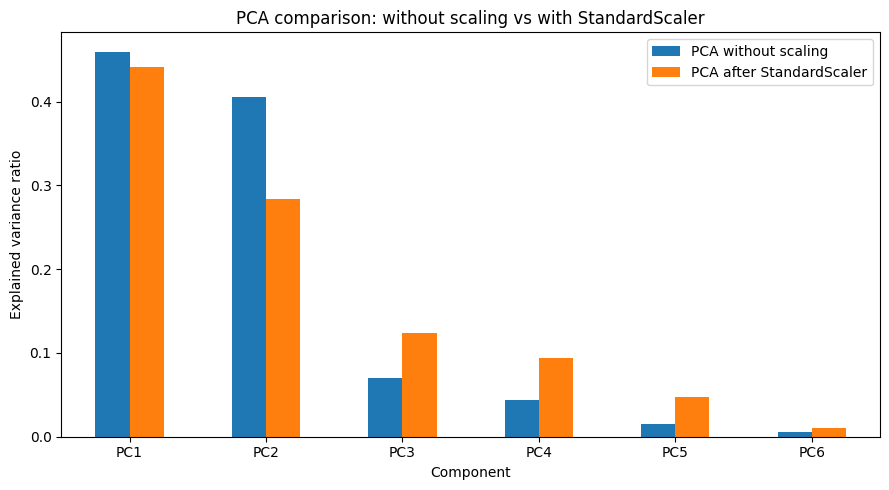

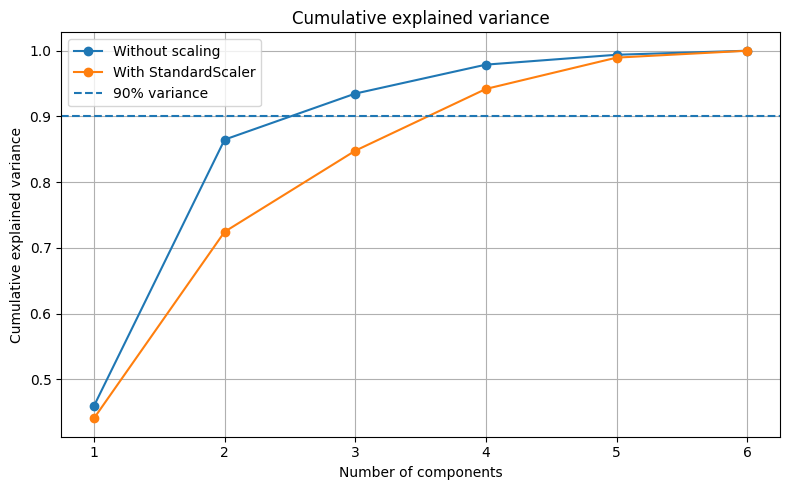

In [7]:
comparison = pd.DataFrame({'Component':[f'PC{i+1}' for i in range(len(features))], 'PCA without scaling':raw_variance, 'PCA after StandardScaler':scaled_variance})
display(comparison.round(4))
comparison.set_index('Component').plot(kind='bar', figsize=(9,5))
plt.ylabel('Explained variance ratio')
plt.title('PCA comparison: without scaling vs with StandardScaler')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
plt.plot(range(1,7), np.cumsum(raw_variance), marker='o', label='Without scaling')
plt.plot(range(1,7), np.cumsum(scaled_variance), marker='o', label='With StandardScaler')
plt.axhline(0.90, linestyle='--', label='90% variance')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Cumulative explained variance')
plt.xticks(range(1,7))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## 7. Visualize customers in the first two principal components

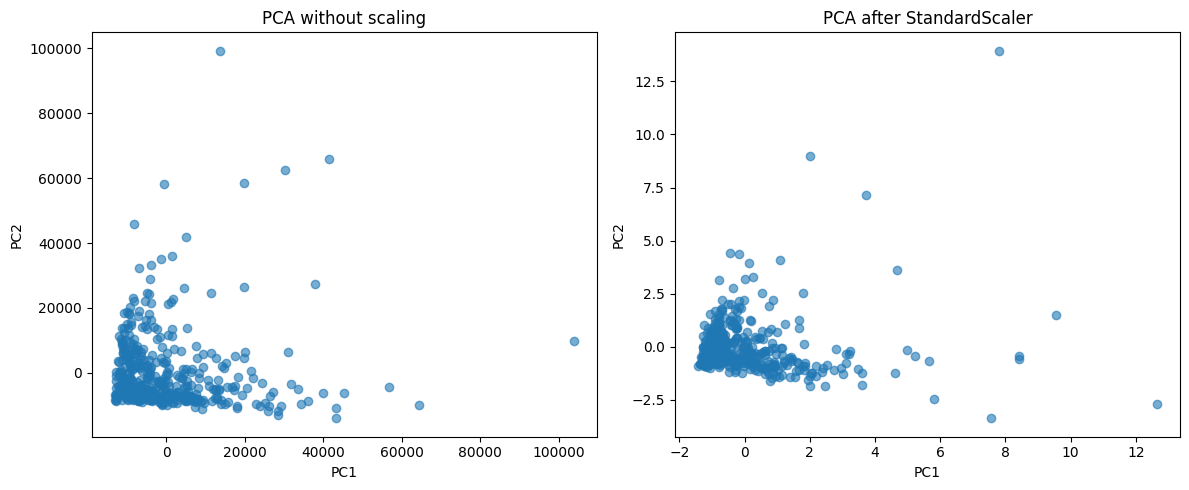

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
axes[0].scatter(X_raw_pca[:,0], X_raw_pca[:,1], alpha=0.6)
axes[0].set_title('PCA without scaling')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[1].scatter(X_scaled_pca[:,0], X_scaled_pca[:,1], alpha=0.6)
axes[1].set_title('PCA after StandardScaler')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
plt.tight_layout(); plt.show()


## 8. Reduce the data to two dimensions
The following creates a two-dimensional representation using the scaled PCA result. The amount of variance retained is printed for interpretation.

In [9]:
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_scaled)
reduced_df = pd.DataFrame(X_2d, columns=['PC1','PC2'])
reduced_df['Channel'] = df['Channel'].values
print('Variance retained by 2 components:', round(pca_2d.explained_variance_ratio_.sum()*100, 2), '%')
display(reduced_df.head())


Variance retained by 2 components: 72.46 %


,PC1,PC2,Channel
0,0.193291,-0.305100,2
1,0.434420,-0.328413,2
2,0.811143,0.815096,2
3,-0.778648,0.652754,1
4,0.166287,1.271434,2


## 9. Conclusion
PCA converts the six original spending features into principal components that summarize variation in the customer data. The comparison demonstrates why scaling matters: PCA without scaling can be dominated by high-variance spending features, while StandardScaler gives each feature comparable initial scale. The exact variance percentages and plots should be taken from the executed notebook output.